# 데이터 로드

- annotation JSON 하나 = 이미지 1장 × 알약 1개입니다. 같은 이미지의 알약이 약 코드별 폴더에 흩어져 있어서 `file_name` 기준으로 합칩니다.
- 경로: `data/train_annotations/<조합>_json/<약코드>/<이미지이름>.json`
- bbox는 COCO 형식 `[x, y, w, h]`(왼쪽 위 기준, 픽셀)입니다.

In [11]:
import json
import re
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import font_manager
from matplotlib.patches import Rectangle

# 노트북은 notebooks/에서 실행되므로 프로젝트 루트를 import 경로에 추가한다.
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.config import PROJECT_ROOT  # noqa: E402

DATA_DIR = PROJECT_ROOT / "data"
TRAIN_IMG_DIR = DATA_DIR / "raw/train_images"
TRAIN_ANN_DIR = DATA_DIR / "raw/train_annotations"
TEST_IMG_DIR = DATA_DIR / "raw/test_images"

# 클래스 이름(한글)이 깨지지 않도록 OS에 설치된 한글 폰트를 고른다.
KOREAN_FONTS = ["AppleGothic", "Malgun Gothic", "NanumGothic"]
installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in KOREAN_FONTS if f in installed_fonts), "sans-serif")
plt.rcParams["axes.unicode_minus"] = False

In [12]:
def load_annotations(ann_dir: Path, img_dir: Path) -> pd.DataFrame:
    """annotation JSON을 모두 읽어 bbox 한 개당 한 행인 DataFrame을 만든다."""
    rows = []
    for json_path in sorted(ann_dir.rglob("*.json")):
        with open(json_path, encoding="utf-8") as f:
            data = json.load(f)
        img = data["images"][0]
        categories = {c["id"]: c["name"] for c in data["categories"]}
        for ann in data["annotations"]:
            x, y, w, h = ann["bbox"]
            rows.append(
                {
                    **img,
                    "image_path": img_dir / img["file_name"],
                    "json_path": json_path,
                    "ann_id": ann["id"],
                    "category_id": ann["category_id"],
                    "category_name": categories.get(ann["category_id"]),
                    "x": x,
                    "y": y,
                    "w": w,
                    "h": h,
                    "area": ann["area"],
                }
            )
    return pd.DataFrame(rows).rename(columns={"id": "image_id"})


ann_df = load_annotations(TRAIN_ANN_DIR, TRAIN_IMG_DIR)
ann_df.head()

,file_name,width,height,imgfile,drug_N,drug_S,back_color,drug_dir,light_color,camera_la,...,image_path,json_path,ann_id,category_id,category_name,x,y,w,h,area
0,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,976,1280,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,K-001900,정상알약,연회색 배경,앞면,주백색,70,...,/Users/yundong-ug/dev/pillbbox/data/raw/train_...,/Users/yundong-ug/dev/pillbbox/data/raw/train_...,133,1900,보령부스파정 5mg,644,845,189,190,35910
1,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,976,1280,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,K-001900,정상알약,연회색 배경,앞면,주백색,75,...,/Users/yundong-ug/dev/pillbbox/data/raw/train_...,/Users/yundong-ug/dev/pillbbox/data/raw/train_...,134,1900,보령부스파정 5mg,148,241,181,181,32761
2,K-001900-016548-019607-029451_0_2_0_2_90_000_2...,976,1280,K-001900-016548-019607-029451_0_2_0_2_90_000_2...,K-001900,정상알약,연회색 배경,앞면,주백색,90,...,/Users/yundong-ug/dev/pillbbox/data/raw/train_...,/Users/yundong-ug/dev/pillbbox/data/raw/train_...,135,1900,보령부스파정 5mg,167,248,184,182,33488
3,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,976,1280,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,K-016548,정상알약,연회색 배경,앞면,주백색,70,...,/Users/yundong-ug/dev/pillbbox/data/raw/train_...,/Users/yundong-ug/dev/pillbbox/data/raw/train_...,136,16548,가바토파정 100mg,144,799,239,239,57121
4,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,976,1280,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,K-016548,정상알약,연회색 배경,앞면,주백색,75,...,/Users/yundong-ug/dev/pillbbox/data/raw/train_...,/Users/yundong-ug/dev/pillbbox/data/raw/train_...,137,16548,가바토파정 100mg,578,222,233,226,52658


In [13]:
# 이미지 한 장당 한 행. 파일 이름의 약 코드 수와 실제 bbox 수를 함께 둔다.
img_df = (
    ann_df.groupby("file_name")
    .agg(
        image_id=("image_id", "first"),
        image_path=("image_path", "first"),
        width=("width", "first"),
        height=("height", "first"),
        n_boxes=("ann_id", "size"),
    )
    .reset_index()
)
img_df["n_codes_in_name"] = img_df["file_name"].str.split("_").str[0].str.count("-")

test_paths = sorted(TEST_IMG_DIR.glob("*.png"), key=lambda p: int(p.stem))

n_classes = ann_df["category_id"].nunique()
disk_names = {p.name for p in TRAIN_IMG_DIR.glob("*.png")}
n_no_ann = len(disk_names - set(img_df["file_name"]))
n_missing = (img_df["n_boxes"] < img_df["n_codes_in_name"]).sum()

display(img_df.head(5))
print(f"train 이미지: {len(img_df)}장, bbox: {len(ann_df)}개, 클래스: {n_classes}개")
print(f"test 이미지: {len(test_paths)}장")
print(f"annotation 없는 train 이미지: {n_no_ann}장")
print(f"파일 이름보다 bbox가 적은 이미지: {n_missing}장")

,file_name,image_id,image_path,width,height,n_boxes,n_codes_in_name
0,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,34,/Users/yundong-ug/dev/pillbbox/data/raw/train_...,976,1280,4,4
1,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,35,/Users/yundong-ug/dev/pillbbox/data/raw/train_...,976,1280,4,4
2,K-001900-016548-019607-029451_0_2_0_2_90_000_2...,36,/Users/yundong-ug/dev/pillbbox/data/raw/train_...,976,1280,4,4
3,K-001900-016548-019607-033009_0_2_0_2_70_000_2...,1228,/Users/yundong-ug/dev/pillbbox/data/raw/train_...,976,1280,4,4
4,K-001900-016548-019607-033009_0_2_0_2_75_000_2...,1230,/Users/yundong-ug/dev/pillbbox/data/raw/train_...,976,1280,4,4


train 이미지: 232장, bbox: 763개, 클래스: 56개
test 이미지: 842장
annotation 없는 train 이미지: 0장
파일 이름보다 bbox가 적은 이미지: 8장


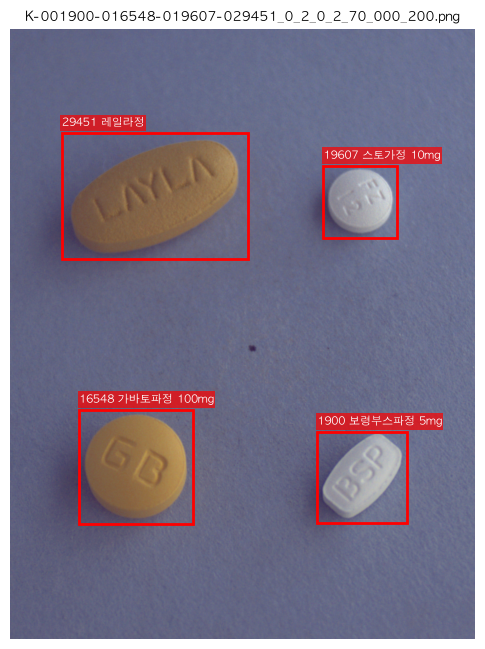

In [14]:
def show_image(file_name: str) -> None:
    """train 이미지 한 장에 bbox와 category_id, 클래스 이름을 그려서 보여준다."""
    rows = ann_df[ann_df["file_name"] == file_name]
    img = cv2.cvtColor(cv2.imread(str(rows["image_path"].iloc[0])), cv2.COLOR_BGR2RGB)
    _, ax = plt.subplots(figsize=(6, 8))
    ax.imshow(img)
    for r in rows.itertuples():
        ax.add_patch(Rectangle((r.x, r.y), r.w, r.h, fill=False, edgecolor="red", linewidth=2))
        ax.text(
            r.x,
            r.y - 8,
            f"{r.category_id} {r.category_name}",
            color="white",
            fontsize=8,
            va="bottom",
            bbox={"facecolor": "red", "alpha": 0.7, "edgecolor": "none", "pad": 1},
        )
    ax.set_title(file_name, fontsize=9)
    ax.axis("off")
    plt.show()


show_image(img_df["file_name"].iloc[0])

# bbox 결측치 확인

- 값 결측: bbox 좌표·category가 비어 있는 행
- 알약 결측: 파일 이름에 있는 약 코드 중 annotation이 없는 것 (`category_id` 32310 = 약 코드 `K-032310`)
- 이상 bbox: 크기 0 이하, 이미지 밖으로 나감, `area`와 `w*h` 불일치

In [15]:
# 1) 값 결측
bbox_cols = ["x", "y", "w", "h", "area", "category_id"]
print("bbox 컬럼별 결측 수")
print(ann_df[bbox_cols].isna().sum().to_string())

# 2) 알약 결측: 파일 이름의 약 코드와 실제 annotation의 약 코드를 비교한다.
ann_codes = ann_df.groupby("file_name")["category_id"].agg(lambda s: {f"K-{c:06d}" for c in s})
missing_df = img_df[["file_name", "n_codes_in_name", "n_boxes"]].copy()
missing_df["missing_codes"] = [
    sorted({f"K-{c}" for c in name.split("_")[0].split("-")[1:]} - ann_codes[name])
    for name in missing_df["file_name"]
]
missing_df = missing_df[missing_df["missing_codes"].str.len() > 0].reset_index(drop=True)
print(f"\n알약 annotation이 빠진 이미지: {len(missing_df)}장")
display(missing_df)

# 3) 이상 bbox
checks = {
    "크기 0 이하": (ann_df["w"] <= 0) | (ann_df["h"] <= 0),
    "이미지 밖": (ann_df["x"] < 0)
    | (ann_df["y"] < 0)
    | (ann_df["x"] + ann_df["w"] > ann_df["width"])
    | (ann_df["y"] + ann_df["h"] > ann_df["height"]),
    "area 불일치": ann_df["area"] != ann_df["w"] * ann_df["h"],
}
bad_df = pd.concat([ann_df[mask].assign(problem=name) for name, mask in checks.items()])
print("\n이상 bbox 수")
print(bad_df["problem"].value_counts().reindex(checks, fill_value=0).to_string())
display(
    bad_df[
        ["problem", "file_name", "category_id", "x", "y", "w", "h", "width", "height", "area"]
    ].reset_index(drop=True)
)

bbox 컬럼별 결측 수
x              0
y              0
w              0
h              0
area           0
category_id    0

알약 annotation이 빠진 이미지: 8장


,file_name,n_codes_in_name,n_boxes,missing_codes
0,K-003351-013900-021325_0_2_0_2_70_000_200.png,3,2,[K-003351]
1,K-003351-013900-036637_0_2_0_2_70_000_200.png,3,2,[K-003351]
2,K-003351-020014-022074_0_2_0_2_90_000_200.png,3,2,[K-020014]
3,K-003351-021325-032310_0_2_0_2_90_000_200.png,3,2,[K-032310]
4,K-003351-032310-038162_0_2_0_2_70_000_200.png,3,2,[K-003351]
5,K-003351-033880-038162_0_2_0_2_75_000_200.png,3,2,[K-033880]
6,K-003351-035206-041768_0_2_0_2_70_000_200.png,3,2,[K-003351]
7,K-003544-004543-012247-016548_0_2_0_2_90_000_2...,4,3,[K-004543]



이상 bbox 수
problem
크기 0 이하     0
이미지 밖       1
area 불일치    6


,problem,file_name,category_id,x,y,w,h,width,height,area
0,이미지 밖,K-003351-016262-018357_0_2_0_2_75_000_200.png,18357,6567,625,311,315,976,1280,97965
1,area 불일치,K-002483-012081-012778-025438_0_2_0_2_90_000_2...,12778,88,48,317,508,976,1280,161096
2,area 불일치,K-003351-019232-029667_0_2_1_2_70_000_200.png,19232,523,201,232,241,976,1280,79112
3,area 불일치,K-003351-019232-035206_0_2_0_2_90_000_200.png,19232,141,801,322,266,976,1280,88312
4,area 불일치,K-003351-021325-033880_0_2_0_2_70_000_200.png,3351,427,839,189,182,976,1280,36288
5,area 불일치,K-003351-033880-038162_0_2_0_2_70_000_200.png,33880,558,195,309,420,976,1280,129480
6,area 불일치,K-003351-033880-038162_0_2_0_2_70_000_200.png,38162,129,269,251,259,976,1280,62009


In [16]:
# 알약 결측 이미지와 이상 bbox 이미지가 겹치는지 확인한다.
missing_names = set(missing_df["file_name"])
bad_names = set(bad_df["file_name"])
overlap_names = missing_names & bad_names
problem_names = missing_names | bad_names

print(f"알약 annotation이 빠진 이미지: {len(missing_names)}장")
print(f"이상 bbox가 있는 이미지: {len(bad_names)}장")
print(f"둘 다 해당하는 이미지: {len(overlap_names)}장 {sorted(overlap_names)}")
print(f"결측·이상 이미지 총: {len(problem_names)}장 / 전체 {len(img_df)}장")

알약 annotation이 빠진 이미지: 8장
이상 bbox가 있는 이미지: 6장
둘 다 해당하는 이미지: 0장 []
결측·이상 이미지 총: 14장 / 전체 232장


# 테이블 결측치 확인

- 대상: `images[]`의 알약 메타데이터 컬럼 (annotation JSON 하나당 한 행)
- 결측은 두 가지로 셉니다. JSON에 키 자체가 없으면 `NaN`, 키는 있는데 값이 `""`이면 빈 문자열입니다.
- `필수여부`는 [data/README.md](../data/README.md)의 스키마 기준입니다. `O`(선택)·`C`(조건부) 컬럼은 비어 있어도 정상일 수 있습니다.

## 확인사항
테이블 데이터의 결측을 봤을 때 채울 수도 있지만, 딱히 채울 필요가 없어보이긴 함.

In [19]:
# load_annotations()에서 붙인 컬럼을 빼면 JSON images[]의 컬럼만 남는다.
ADDED_COLS = ["image_path", "json_path", "ann_id", "category_id", "category_name"]
ADDED_COLS += ["x", "y", "w", "h", "area"]
# 결측 행이 어떤 이미지·알약인지 알아볼 수 있게 함께 보여줄 컬럼
ID_COLS = ["file_name", "image_id", "dl_mapping_code", "dl_name", "drug_dir", "back_color"]

# data/README.md의 스키마 표에서 images[] 키의 필수여부와 설명을 읽는다.
# 예: | `images[].drug_shape` | String | M | 알약 모양 |
schema_pattern = re.compile(r"^\| `images\[\]\.(\w+)` \| [^|]+ \| (\w) \| ([^|]+?) \|$")
schema_rows = [
    m.groups()
    for line in (DATA_DIR / "README.md").read_text(encoding="utf-8").splitlines()
    if (m := schema_pattern.match(line.strip()))
]
schema_df = pd.DataFrame(schema_rows, columns=["키", "필수여부", "설명"]).set_index("키")
schema_df.loc["image_id"] = schema_df.loc["id"]  # load_annotations()에서 id를 image_id로 바꿨다.

# ann_df는 bbox(알약) 한 개당 한 행이다. 메타데이터도 그 알약에 대한 정보다.
meta_df = ann_df.drop(columns=ADDED_COLS)
is_blank = meta_df.apply(lambda s: s.notna() & s.astype(str).str.strip().eq(""))

# NaN(키 없음)은 정보 누락, 빈 문자열은 "해당 없음"일 수 있어서 비율을 따로 본다.
n_nan = meta_df.isna().sum()
n_blank = is_blank.sum()
null_df = pd.DataFrame(
    {
        "NaN": n_nan,
        "NaN 비율(%)": (n_nan / len(meta_df) * 100).round(1),
        "빈 문자열": n_blank,
        "빈 문자열 비율(%)": (n_blank / len(meta_df) * 100).round(1),
        "결측 비율(%)": ((n_nan + n_blank) / len(meta_df) * 100).round(1),
    }
)
null_df = null_df.join(schema_df)
null_df = null_df[null_df["결측 비율(%)"] > 0].sort_values(["결측 비율(%)", "NaN"], ascending=False)

print(
    f"전체 {len(meta_df)}행(bbox, 이미지 {meta_df['file_name'].nunique()}장), "
    f"{meta_df.shape[1]}개 컬럼 중 결측이 있는 컬럼: {len(null_df)}개"
)
display(null_df)

# 키 자체가 빠진(NaN) 행이 어떤 이미지·알약인지 본다.
is_nan_row = meta_df.isna().any(axis=1)
nan_cols = sorted(meta_df.columns[meta_df.isna().any()])
nan_rows_df = ann_df.loc[is_nan_row, ID_COLS].copy()
nan_rows_df["json_path"] = [
    Path(p).relative_to(TRAIN_ANN_DIR).as_posix() for p in ann_df.loc[is_nan_row, "json_path"]
]
nan_rows_df["빠진 키 수"] = meta_df[is_nan_row].isna().sum(axis=1)
nan_rows_df = nan_rows_df.sort_values("file_name").reset_index(drop=True)

print(f"\n키가 빠진 행: {len(nan_rows_df)}개, 이미지 {nan_rows_df['file_name'].nunique()}장")
display(nan_rows_df)

print(f"\n빠진 키 {len(nan_cols)}개")
display(schema_df.reindex(nan_cols).rename_axis("빠진 키"))

전체 763행(bbox, 이미지 232장), 50개 컬럼 중 결측이 있는 컬럼: 22개


,NaN,NaN 비율(%),빈 문자열,빈 문자열 비율(%),결측 비율(%),필수여부,설명
mark_code_back_anal,18,2.4,745,97.6,100.0,M,알약 뒷면마크 형태
mark_code_back_img,18,2.4,745,97.6,100.0,M,알약 뒷면마크 이미지
mark_code_front,18,2.4,745,97.6,100.0,M,알약 앞면마크 코드
mark_code_back,18,2.4,745,97.6,100.0,M,알약 뒷면마크 코드
di_company_mf_en,0,0.0,724,94.9,94.9,O,위탁제조사명(영어)
color_class2,18,2.4,693,90.8,93.2,O,색상 2
mark_code_front_anal,18,2.4,642,84.1,86.5,M,알약 앞면마크 형태
mark_code_front_img,18,2.4,642,84.1,86.5,M,알약 앞면마크 이미지
line_back,18,2.4,630,82.6,84.9,M,알약 뒷면분할선 여부
di_company_mf,0,0.0,637,83.5,83.5,M,위탁제조사명



키가 빠진 행: 18개, 이미지 18장


,file_name,image_id,dl_mapping_code,dl_name,drug_dir,back_color,json_path,빠진 키 수
0,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,34,K-016548,가바토파정 100mg,앞면,연회색 배경,K-001900-016548-019607-029451_json/K-016548/K-...,18
1,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,35,K-016548,가바토파정 100mg,앞면,연회색 배경,K-001900-016548-019607-029451_json/K-016548/K-...,18
2,K-001900-016548-019607-029451_0_2_0_2_90_000_2...,36,K-016548,가바토파정 100mg,앞면,연회색 배경,K-001900-016548-019607-029451_json/K-016548/K-...,18
3,K-001900-016548-019607-033009_0_2_0_2_70_000_2...,1228,K-016548,가바토파정 100mg,앞면,연회색 배경,K-001900-016548-019607-033009_json/K-016548/K-...,18
4,K-001900-016548-019607-033009_0_2_0_2_75_000_2...,1230,K-016548,가바토파정 100mg,앞면,연회색 배경,K-001900-016548-019607-033009_json/K-016548/K-...,18
5,K-001900-016548-019607-033009_0_2_0_2_90_000_2...,1229,K-016548,가바토파정 100mg,앞면,연회색 배경,K-001900-016548-019607-033009_json/K-016548/K-...,18
6,K-001900-016548-021771-027926_0_2_0_2_70_000_2...,76,K-016548,가바토파정 100mg,앞면,연회색 배경,K-001900-016548-021771-027926_json/K-016548/K-...,18
7,K-001900-016548-021771-027926_0_2_0_2_75_000_2...,77,K-016548,가바토파정 100mg,앞면,연회색 배경,K-001900-016548-021771-027926_json/K-016548/K-...,18
8,K-001900-016548-021771-027926_0_2_0_2_90_000_2...,78,K-016548,가바토파정 100mg,앞면,연회색 배경,K-001900-016548-021771-027926_json/K-016548/K-...,18
9,K-001900-016548-024850-029345_0_2_0_2_70_000_2...,1001,K-016548,가바토파정 100mg,앞면,연회색 배경,K-001900-016548-024850-029345_json/K-016548/K-...,18



빠진 키 18개


,필수여부,설명
빠진 키,,
change_date,O,변경일자
chart,M,알약 제형
color_class1,M,색상 1
color_class2,O,색상 2
drug_shape,M,알약 모양
form_code_name,M,정제 분류명
img_key,M,이미지 링크
img_regist_ts,O,약학정보원 이미지 생성일
line_back,M,알약 뒷면분할선 여부


# 카메라 각도·촬영 조건 확인

- `camera_la`(카메라 위도), `camera_lo`(카메라 경도) 등 촬영 조건이 학습에 쓸 만한 정보인지 봅니다.
- test 이미지에는 JSON이 없으므로 촬영 조건을 모델 입력으로 쓸 수는 없습니다.
- 파일 이름 앞부분(`K-001900-016548-...`)이 알약 조합입니다. 같은 조합을 각도만 바꿔 여러 번 찍었다면 train/val을 조합 단위로 나눠야 합니다.

In [20]:
# 1) 촬영 조건 값 분포 (이미지 한 장당 한 행)
SHOT_COLS = ["camera_la", "camera_lo", "size", "back_color", "light_color"]
shot_df = ann_df.drop_duplicates("file_name")
print(f"이미지 {len(shot_df)}장 기준 촬영 조건 값")
for col in SHOT_COLS:
    print(f"  {col}: {shot_df[col].value_counts().sort_index().to_dict()}")

# 2) 각도별 bbox 크기·비율: 각도에 따라 알약이 커지거나 찌그러지는지 본다.
angle_df = (
    ann_df.assign(ratio=ann_df[["w", "h"]].max(axis=1) / ann_df[["w", "h"]].min(axis=1))
    .groupby("camera_la")
    .agg(
        n_images=("file_name", "nunique"),
        n_boxes=("ann_id", "size"),
        w_mean=("w", "mean"),
        h_mean=("h", "mean"),
        ratio_mean=("ratio", "mean"),
    )
    .round(3)
)
print("\n각도별 bbox 크기 (ratio = 긴 변 / 짧은 변)")
display(angle_df)

# 3) 같은 알약 조합을 몇 장 찍었는지: 2장 이상이면 각도만 다른 거의 같은 이미지다.
combo = img_df["file_name"].str.split("_").str[0]
combo_sizes = img_df.groupby(combo).size()
print(f"알약 조합: {combo_sizes.size}개 (이미지 {len(img_df)}장)")
print(f"조합당 이미지 수별 조합 개수: {combo_sizes.value_counts().sort_index().to_dict()}")
print(f"각도만 다른 이미지가 있는 조합: {(combo_sizes > 1).sum()}개")

이미지 232장 기준 촬영 조건 값
  camera_la: {70: 72, 75: 75, 90: 85}
  camera_lo: {0: 232}
  size: {200: 232}
  back_color: {'연회색 배경': 232}
  light_color: {'주백색': 232}

각도별 bbox 크기 (ratio = 긴 변 / 짧은 변)


,n_images,n_boxes,w_mean,h_mean,ratio_mean
camera_la,,,,,
70,72,237,248.620,265.055,1.223
75,75,249,251.827,268.100,1.228
90,85,277,249.560,264.271,1.225


알약 조합: 114개 (이미지 232장)
조합당 이미지 수별 조합 개수: {1: 36, 2: 38, 3: 40}
각도만 다른 이미지가 있는 조합: 78개


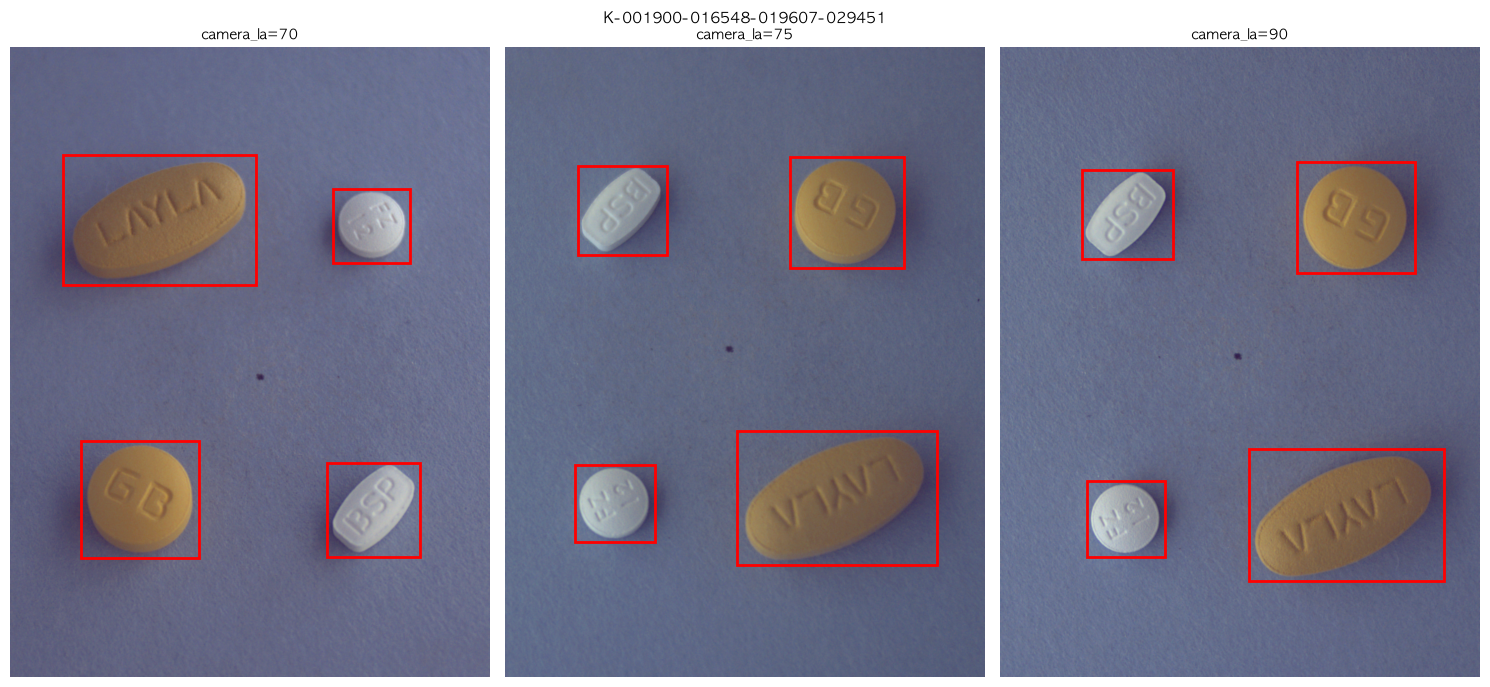

In [21]:
# 3장을 찍은 조합 하나를 골라 각도별 이미지를 나란히 본다.
sample_combo = combo_sizes[combo_sizes == 3].index[0]
sample_names = sorted(img_df.loc[combo == sample_combo, "file_name"])

_, axes = plt.subplots(1, len(sample_names), figsize=(5 * len(sample_names), 7))
for ax, name in zip(axes, sample_names, strict=True):
    rows = ann_df[ann_df["file_name"] == name]
    img = cv2.cvtColor(cv2.imread(str(rows["image_path"].iloc[0])), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    for r in rows.itertuples():
        ax.add_patch(Rectangle((r.x, r.y), r.w, r.h, fill=False, edgecolor="red", linewidth=2))
    ax.set_title(f"camera_la={rows['camera_la'].iloc[0]}", fontsize=10)
    ax.axis("off")
plt.suptitle(sample_combo, fontsize=11)
plt.tight_layout()
plt.show()

# 알약 실제 크기 상관계수

- `thick`(두께), `leng_long`(장축), `leng_short`(단축)은 mm 단위이고 클래스마다 고정값입니다.
- 크기끼리의 상관은 클래스 단위(클래스당 한 행)로, bbox 픽셀 크기와의 상관은 bbox 단위로 봅니다.
- 값이 0인 클래스와 이상 bbox는 빼고 계산합니다.

In [22]:
SIZE_COLS = ["thick", "leng_long", "leng_short"]
PX_COLS = ["long_px", "short_px"]

size_df = ann_df.assign(
    long_px=ann_df[["w", "h"]].max(axis=1),
    short_px=ann_df[["w", "h"]].min(axis=1),
)

# 크기가 0이면 값이 없는 것으로 본다.
has_zero = (size_df[SIZE_COLS] == 0).any(axis=1)
zero_classes = size_df.loc[has_zero, ["dl_mapping_code", "dl_name"]].drop_duplicates()
print(f"크기가 0인 bbox: {has_zero.sum()}개")
display(zero_classes.reset_index(drop=True))

# 이상 bbox(이미지 밖, area 불일치)도 뺀다.
size_df = size_df[~has_zero & ~size_df.index.isin(bad_df.index)]


def show_corr(df: pd.DataFrame, title: str) -> None:
    """상관계수 행렬을 -1~1 색으로 칠해서 보여준다."""
    print(f"\n{title}")
    display(df.corr().style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1).format("{:.3f}"))


# 1) 실제 크기끼리: 클래스당 한 행
class_size_df = size_df.drop_duplicates("category_id")
show_corr(class_size_df[SIZE_COLS], f"실제 크기끼리 상관 (클래스 {len(class_size_df)}개)")

# 2) 실제 크기 vs bbox 픽셀 크기: bbox당 한 행
show_corr(size_df[SIZE_COLS + PX_COLS], f"실제 크기 vs bbox 픽셀 크기 (bbox {len(size_df)}개)")

# 3) 1mm가 몇 픽셀인지: 각도마다 거의 같으면 촬영 거리가 고정된 것이다.
size_df = size_df.assign(
    long_px_per_mm=size_df["long_px"] / size_df["leng_long"],
    short_px_per_mm=size_df["short_px"] / size_df["leng_short"],
)
print("\n각도별 1mm당 픽셀 수")
display(
    size_df.groupby("camera_la")[["long_px_per_mm", "short_px_per_mm"]]
    .agg(["mean", "std"])
    .round(2)
)

크기가 0인 bbox: 18개


,dl_mapping_code,dl_name
0,K-016548,가바토파정 100mg



실제 크기끼리 상관 (클래스 55개)


,thick,leng_long,leng_short
thick,1.000,0.841,0.525
leng_long,0.841,1.000,0.409
leng_short,0.525,0.409,1.000



실제 크기 vs bbox 픽셀 크기 (bbox 738개)


,thick,leng_long,leng_short,long_px,short_px
thick,1.000,0.867,0.421,0.837,0.729
leng_long,0.867,1.000,0.279,0.977,0.798
leng_short,0.421,0.279,1.000,0.360,0.604
long_px,0.837,0.977,0.360,1.000,0.772
short_px,0.729,0.798,0.604,0.772,1.000



각도별 1mm당 픽셀 수


long_px_per_mm       short_px_per_mm      
                    mean   std            mean   std
camera_la                                           
70                 24.80  2.21           31.95  6.94
75                 25.24  1.89           31.74  7.16
90                 24.89  1.83           31.48  7.52

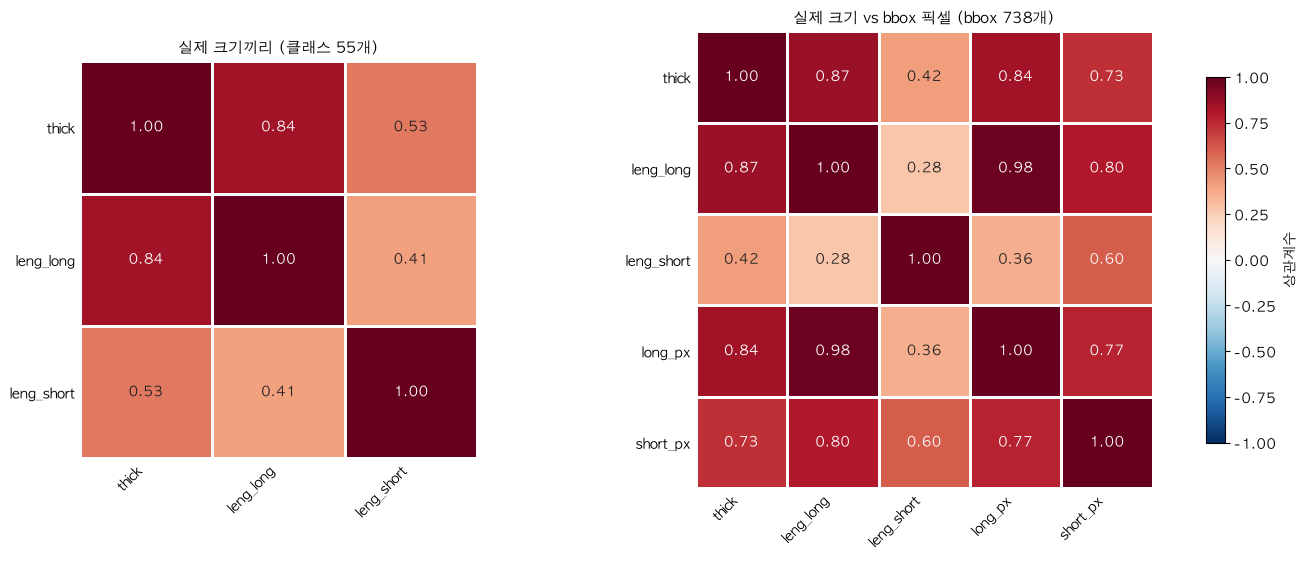

In [23]:
def plot_corr_heatmap(ax: plt.Axes, corr: pd.DataFrame, title: str):
    """상관계수 행렬을 히트맵으로 그리고 칸마다 값을 적는다. 색 막대용 mesh를 반환한다."""
    mesh = ax.pcolormesh(corr.values, cmap="RdBu_r", vmin=-1, vmax=1, edgecolors="white", lw=2)
    for i, j in [(i, j) for i in range(len(corr)) for j in range(len(corr))]:
        value = corr.iat[i, j]
        color = "white" if abs(value) >= 0.6 else "#1f1f1f"
        ax.text(j + 0.5, i + 0.5, f"{value:.2f}", ha="center", va="center", color=color)
    ax.set_xticks([k + 0.5 for k in range(len(corr))], corr.columns, rotation=45, ha="right")
    ax.set_yticks([k + 0.5 for k in range(len(corr))], corr.index)
    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.tick_params(length=0)
    ax.set_frame_on(False)
    ax.set_title(title, fontsize=11)
    return mesh


fig, axes = plt.subplots(
    1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [3, 5]}, layout="constrained"
)
plot_corr_heatmap(
    axes[0], class_size_df[SIZE_COLS].corr(), f"실제 크기끼리 (클래스 {len(class_size_df)}개)"
)
mesh = plot_corr_heatmap(
    axes[1], size_df[SIZE_COLS + PX_COLS].corr(), f"실제 크기 vs bbox 픽셀 (bbox {len(size_df)}개)"
)
fig.colorbar(mesh, ax=axes, shrink=0.8, label="상관계수")
plt.show()